# Research Results and Statistical Analysis

## Comparative Evaluation of Machine Learning Models
## for Flow-Based DDoS Attack Detection

This notebook presents the experimental results of the research.

The analysis includes:
- Raw benchmark data ingestion.
- Warm-up filtering.
- Statistical aggregation.
- Median, p95 and p99 calculation.
- Bootstrap 95% confidence intervals.
- Error-rate monitoring.
- Scientific visualization.

Random seed: 42.

In [1]:
import sys
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

RAW_PATH = ROOT / "data/raw/test_run.jsonl"
PROCESSED_PATH = ROOT / "data/processed/metrics_summary.csv"
FIGURES_PATH = ROOT / "reports/figures"

FIGURES_PATH.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="paper")

print("Project root:", ROOT)
print("Random seed:", SEED)


Project root: /Users/moldirtolegenova/Documents/task2/research_methods-
Random seed: 42


## 1. Data Ingestion

The raw benchmark data is stored in JSON Lines format.

Each line represents one experimental measurement.

The dataset contains both warm-up and evaluation runs.

Warm-up runs are excluded because initial model execution
may introduce cold-start latency.

In [2]:
records = []

with open(RAW_PATH, "r", encoding="utf-8") as file:
    for line in file:
        if line.strip():
            records.append(json.loads(line))

df = pd.DataFrame(records)

print("Total raw records:", len(df))
display(df.head())

Total raw records: 12000


,run_id,fold,model,phase,is_warmup,load_rps,batch_size,latency_ms,throughput_rps,accuracy,precision,recall,f1_score,fpr,error,status_code
0,fold_1_Logistic Regression_1_0,1,Logistic Regression,warmup,True,1,1,2.6131,1913.436156,1.0,1.0,1.0,1.0,0.0,False,200
1,fold_1_Logistic Regression_1_1,1,Logistic Regression,warmup,True,1,1,2.1714,2302.661874,1.0,1.0,1.0,1.0,0.0,False,200
2,fold_1_Logistic Regression_1_2,1,Logistic Regression,warmup,True,1,1,2.0825,2400.960490,1.0,1.0,1.0,1.0,0.0,False,200
3,fold_1_Logistic Regression_1_3,1,Logistic Regression,warmup,True,1,1,2.0356,2456.278367,1.0,1.0,1.0,1.0,0.0,False,200
4,fold_1_Logistic Regression_1_4,1,Logistic Regression,warmup,True,1,1,4.0470,1235.483120,1.0,1.0,1.0,1.0,0.0,False,200


In [3]:
print("Before filtering:", len(df))

warmup_count = df["is_warmup"].astype(bool).sum()

df_eval = df[
    (df["phase"] == "evaluation") &
    (~df["is_warmup"].astype(bool))
].copy()

print("Warm-up records removed:", warmup_count)
print("Evaluation records:", len(df_eval))

assert len(df_eval) > 0, "No evaluation records found!"

display(df_eval.head())

Before filtering: 12000
Warm-up records removed: 2400
Evaluation records: 9600


,run_id,fold,model,phase,is_warmup,load_rps,batch_size,latency_ms,throughput_rps,accuracy,precision,recall,f1_score,fpr,error,status_code
5,fold_1_Logistic Regression_1_5,1,Logistic Regression,evaluation,False,1,1,2.6184,1909.563154,1.0,1.0,1.0,1.0,0.0,False,200
6,fold_1_Logistic Regression_1_6,1,Logistic Regression,evaluation,False,1,1,2.2016,2271.075581,1.0,1.0,1.0,1.0,0.0,False,200
7,fold_1_Logistic Regression_1_7,1,Logistic Regression,evaluation,False,1,1,2.1835,2289.901556,1.0,1.0,1.0,1.0,0.0,False,200
8,fold_1_Logistic Regression_1_8,1,Logistic Regression,evaluation,False,1,1,2.0835,2399.808112,1.0,1.0,1.0,1.0,0.0,False,200
9,fold_1_Logistic Regression_1_9,1,Logistic Regression,evaluation,False,1,1,2.0625,2424.242164,1.0,1.0,1.0,1.0,0.0,False,200


## 2. Data Quality and Error Analysis

Failed evaluation runs are tracked as a guardrail metric.

The error rate is calculated as:

Error Rate = Failed Evaluation Runs / Total Evaluation Runs

Only successful inference measurements are used
for latency and throughput statistics.

In [4]:
total_runs = len(df_eval)

failed_runs = df_eval["error"].astype(bool).sum()

error_rate = failed_runs / total_runs

print("Total evaluation runs:", total_runs)
print("Failed runs:", failed_runs)
print(f"Error rate: {error_rate:.4%}")

error_summary = (
    df_eval.groupby("model")
    .agg(
        total_runs=("error", "count"),
        errors=("error", "sum")
    )
)

error_summary["error_rate"] = (
    error_summary["errors"] / error_summary["total_runs"]
)

display(error_summary)

Total evaluation runs: 9600
Failed runs: 0
Error rate: 0.0000%


,total_runs,errors,error_rate
model,,,
Decision Tree,2400,0,0.0
Logistic Regression,2400,0,0.0
Random Forest,2400,0,0.0
XGBoost,2400,0,0.0


## 3. Statistical Aggregation

The following descriptive statistics are calculated:

- Median: central value of the distribution.
- p95: 95th percentile.
- p99: 99th percentile.
- 95% bootstrap confidence interval.

The confidence interval is estimated using
5000 bootstrap resamples and a fixed random seed.

In [5]:
def bootstrap_ci(values, iterations=5000, statistic=np.median):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan, np.nan

    if len(values) == 1:
        return float(values[0]), float(values[0])

    rng = np.random.default_rng(SEED)

    samples = rng.choice(
        values,
        size=(iterations, len(values)),
        replace=True
    )

    estimates = statistic(samples, axis=1)

    return (
        float(np.percentile(estimates, 2.5)),
        float(np.percentile(estimates, 97.5))
    )

In [6]:
successful = df_eval[
    ~df_eval["error"].astype(bool)
].copy()

latency_results = []

for (model, batch), group in successful.groupby(
    ["model", "batch_size"]
):

    values = group["latency_ms"].dropna().to_numpy()

    ci_low, ci_high = bootstrap_ci(values)

    latency_results.append({
        "model": model,
        "batch_size": batch,
        "count": len(values),
        "median_ms": np.median(values),
        "p95_ms": np.percentile(values, 95),
        "p99_ms": np.percentile(values, 99),
        "ci95_low": ci_low,
        "ci95_high": ci_high
    })

latency_summary = pd.DataFrame(latency_results)

display(latency_summary)

,model,batch_size,count,median_ms,p95_ms,p99_ms,ci95_low,ci95_high
0,Decision Tree,1,400,1.80960,2.985440,4.026330,1.771200,1.853850
1,Decision Tree,2,400,1.74090,2.818025,2.969640,1.723300,1.770800
2,Decision Tree,4,400,1.76135,2.821460,3.121834,1.740000,1.793550
3,Decision Tree,8,400,1.72225,2.618025,2.834342,1.708295,1.732300
4,Decision Tree,16,400,1.77130,2.729365,2.931931,1.747700,1.798700
5,Decision Tree,32,400,1.80595,2.859465,3.087105,1.774700,1.879800
6,Logistic Regression,1,400,2.20245,3.380305,4.165645,2.164000,2.254700
7,Logistic Regression,2,400,2.11675,3.501195,3.839153,2.100400,2.137550
8,Logistic Regression,4,400,2.11270,3.362795,3.714156,2.082800,2.138250
9,Logistic Regression,8,400,2.09855,3.228580,3.527651,2.082900,2.122601


In [7]:
classification_results = []

for model, group in df_eval.groupby("model"):

    # One classification result per independent CV fold.
    folds = group.drop_duplicates(subset=["fold"])

    for metric in ["accuracy", "precision", "recall",
                   "f1_score", "fpr"]:

        values = folds[metric].dropna().to_numpy()

        low, high = bootstrap_ci(
            values,
            statistic=np.mean
        )

        classification_results.append({
            "model": model,
            "metric": metric,
            "mean": np.mean(values),
            "ci95_low": low,
            "ci95_high": high
        })

classification_summary = pd.DataFrame(
    classification_results
)

display(classification_summary)

,model,metric,mean,ci95_low,ci95_high
0,Decision Tree,accuracy,1.000000,1.000000,1.00
1,Decision Tree,precision,1.000000,1.000000,1.00
2,Decision Tree,recall,1.000000,1.000000,1.00
3,Decision Tree,f1_score,1.000000,1.000000,1.00
4,Decision Tree,fpr,0.000000,0.000000,0.00
5,Logistic Regression,accuracy,1.000000,1.000000,1.00
6,Logistic Regression,precision,1.000000,1.000000,1.00
7,Logistic Regression,recall,1.000000,1.000000,1.00
8,Logistic Regression,f1_score,1.000000,1.000000,1.00
9,Logistic Regression,fpr,0.000000,0.000000,0.00


## 4. Visualization

The first figure presents inference latency
under different batch sizes.

The shaded region represents the bootstrap
95% confidence interval of the median.

The second figure compares the distribution
of individual evaluation latency measurements
across classifiers.

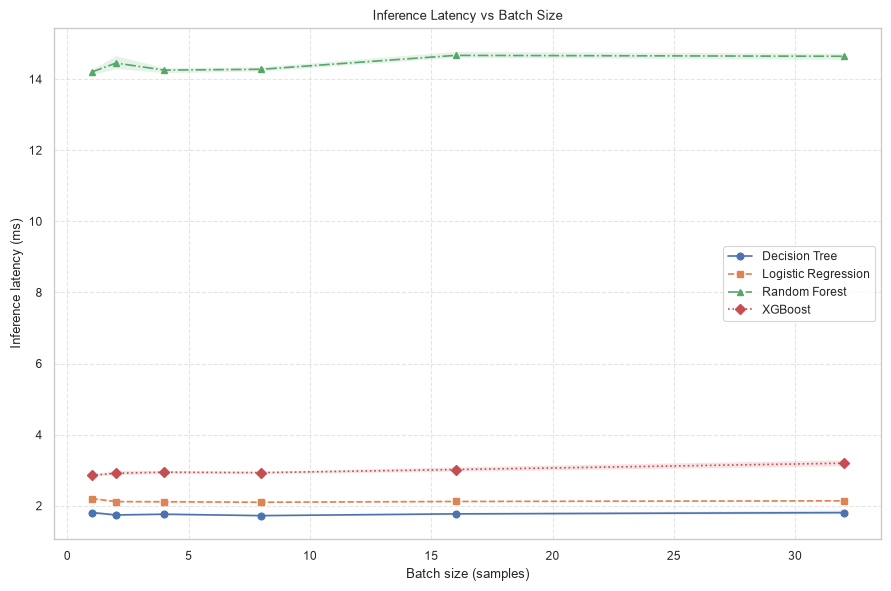

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))

models = latency_summary["model"].unique()

markers = ["o", "s", "^", "D"]
linestyles = ["-", "--", "-.", ":"]

for i, model in enumerate(models):

    part = latency_summary[
        latency_summary["model"] == model
    ].sort_values("batch_size")

    x = part["batch_size"].to_numpy()
    y = part["median_ms"].to_numpy()
    low = part["ci95_low"].to_numpy()
    high = part["ci95_high"].to_numpy()

    ax.plot(
        x, y,
        marker=markers[i % len(markers)],
        linestyle=linestyles[i % len(linestyles)],
        label=model
    )

    ax.fill_between(x, low, high, alpha=0.15)

ax.set_title("Inference Latency vs Batch Size")
ax.set_xlabel("Batch size (samples)")
ax.set_ylabel("Inference latency (ms)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "fig1_latency_vs_load.pdf",
    bbox_inches="tight"
)

plt.savefig(
    FIGURES_PATH / "fig1_latency_vs_load.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

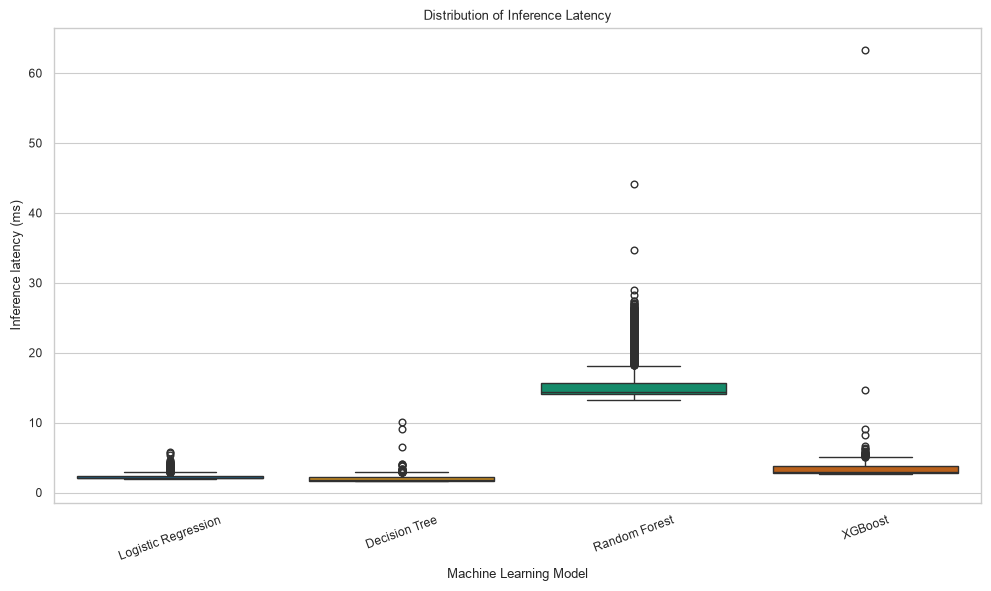

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=successful,
    x="model",
    y="latency_ms",
    hue="model",
    palette="colorblind",
    legend=False,
    ax=ax
)

ax.set_title("Distribution of Inference Latency")
ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Inference latency (ms)")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "fig2_distribution_boxplot.pdf",
    bbox_inches="tight"
)

plt.savefig(
    FIGURES_PATH / "fig2_distribution_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import subprocess

subprocess.run(
    [sys.executable, str(ROOT / "src/process_data.py")],
    check=True
)

final_summary = pd.read_csv(PROCESSED_PATH)

display(final_summary)

print("Final statistical summary exported.")

Final summary saved: /Users/moldirtolegenova/Documents/task2/research_methods-/data/processed/metrics_summary.csv


,model,batch_size,count,median_ms,p95_ms,p99_ms,ci95_low,ci95_high,total_runs,errors,error_rate
0,Decision Tree,1,400,1.80960,2.985440,4.026330,1.771200,1.853850,2400,0,0.0
1,Decision Tree,2,400,1.74090,2.818025,2.969640,1.723300,1.770800,2400,0,0.0
2,Decision Tree,4,400,1.76135,2.821460,3.121834,1.740000,1.793550,2400,0,0.0
3,Decision Tree,8,400,1.72225,2.618025,2.834342,1.708295,1.732300,2400,0,0.0
4,Decision Tree,16,400,1.77130,2.729365,2.931931,1.747700,1.798700,2400,0,0.0
5,Decision Tree,32,400,1.80595,2.859465,3.087105,1.774700,1.879800,2400,0,0.0
6,Logistic Regression,1,400,2.20245,3.380305,4.165645,2.164000,2.254700,2400,0,0.0
7,Logistic Regression,2,400,2.11675,3.501195,3.839153,2.100400,2.137550,2400,0,0.0
8,Logistic Regression,4,400,2.11270,3.362795,3.714156,2.082800,2.138250,2400,0,0.0
9,Logistic Regression,8,400,2.09855,3.228580,3.527651,2.082900,2.122601,2400,0,0.0


## 5. Results and Discussion

The experimental results provide a comparison
of the computational performance of the selected
machine learning classifiers.

Latency measurements show how inference time
changes with batch size.

The boxplot provides information about the
distribution and variability of inference latency.

The classification metrics provide a separate
evaluation of detection quality.

The error rate is monitored as a guardrail metric.

The results should be interpreted in the context
of the dataset size and experimental setup.

A small sample dataset limits the generalizability
of the findings to real-world network traffic.